# Notebook 3 · Hito 2 — Divergencia de velocidades y torques en la singularidad de muñeca (q5 = 0)

**ABB IRB 120 · IMT-342 Robótica · Pasaporte del Hito 2**

Pasaporte: demostrar la divergencia analítica de velocidades y torques en la singularidad `q5 = 0 rad`.
Todo se calcula con el código propio del proyecto (paquete `irb120/`: DH, Pieper, Jacobiano, dinámica y LSPB), sin MoveIt ni librerías de robótica.

**Idea analítica.** Tomando el centro de muñeca como referencia, el Jacobiano es triangular por bloques:

$$\det J(q) = \det J_{p}^{brazo}(q_1,q_2,q_3)\cdot\det[z_3\; z_4\; z_5] = -\sin q_5\;\det J_{p}^{brazo}$$

Con $q_5=0$ los ejes 4 y 6 quedan colineales, $J$ pierde rango y $\dot q = J^{-1}v$ crece como $1/|\sin q_5|$.
Las aceleraciones articulares ($\ddot q = J^{-1}(a-\dot J\dot q)$) crecen como $1/\sin^2 q_5$ y, con ellas, los torques $\tau = M\ddot q + c + g$.

In [1]:
import sys
from pathlib import Path
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().resolve().parent))   # carpeta hito2/ (paquete irb120)

from irb120.dh import forward_kinematics
from irb120 import dynamics
from irb120 import jacobian as J
from irb120.pieper import inverse_kinematics
from irb120.lspb import plan_lspb

np.set_printoptions(precision=4, suppress=True)
Q_BASE = np.deg2rad([30.0, -20.0, 15.0, 40.0, -35.0, 60.0])
TWIST = np.array([0.10, 0.05, 0.02, 0.30, 0.20, 0.10])    # [v (m/s); w (rad/s)] constante
ACCEL = np.array([0.20, 0.10, 0.10, 0.50, 0.40, 0.30])    # [a (m/s^2); alpha (rad/s^2)]

def with_q5(value):
    q = Q_BASE.copy(); q[4] = value
    return q

## 1. Factorización analítica del determinante
Comprobación numérica de $\det J = -\sin q_5\,\det J_p^{brazo}$ en 5 posturas aleatorias.

In [2]:
rng = np.random.default_rng(342)
print(f"{'det J':>14} {'-sin(q5)*det(Jp_brazo)':>26} {'error':>10}")
for _ in range(5):
    q = rng.uniform(-1.0, 1.0, 6)
    lhs, rhs = J.determinant(q), -np.sin(q[4]) * J.arm_position_determinant(q)
    print(f"{lhs:14.6e} {rhs:26.6e} {abs(lhs-rhs):10.1e}")
    assert abs(lhs - rhs) < 1e-10

         det J     -sin(q5)*det(Jp_brazo)      error
  2.304526e-04               2.304526e-04    1.7e-18
  2.631915e-03               2.631915e-03    3.9e-18
 -1.826816e-02              -1.826816e-02    1.0e-17
  3.512035e-03               3.512035e-03    3.0e-18
  3.836240e-03               3.836240e-03    2.2e-18


## 2. Barrido de q5 → 0 con q1…q4, q6 fijos
Twist cartesiano constante $[v;\omega]$: el $\dot q$ requerido y el número de condición explotan.

Pendiente log-log de ||q_dot|| vs q5: -0.968  (teoria: -1)
||q_dot|| en q5=1e-1: 2.68 rad/s
||q_dot|| en q5=1e-6: 1.97e+05 rad/s


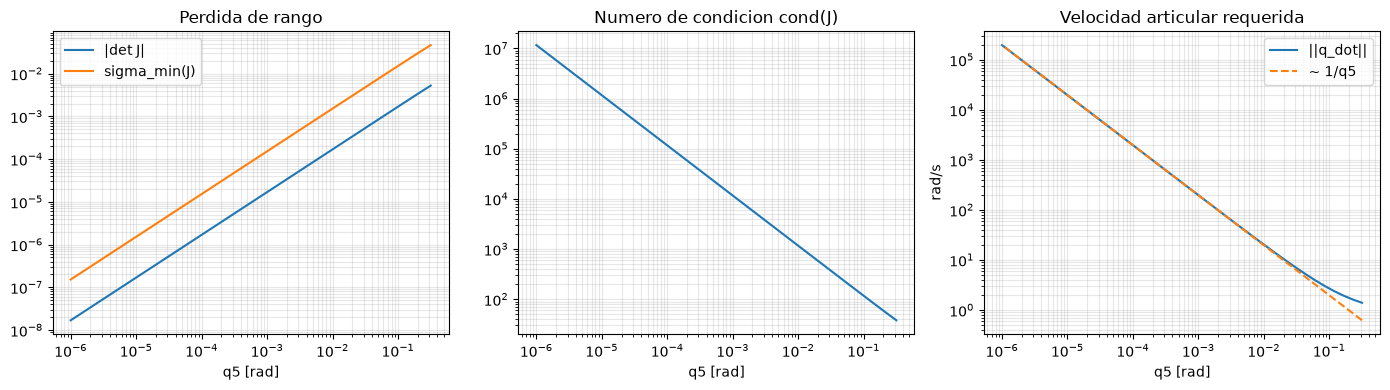

In [3]:
q5_values = np.logspace(-0.5, -6, 40)
sigma_min = np.array([J.smallest_singular_value(with_q5(e)) for e in q5_values])
cond = np.array([J.condition_number(with_q5(e)) for e in q5_values])
qdot_norm = np.array([np.linalg.norm(J.joint_velocity(with_q5(e), TWIST)) for e in q5_values])
det_abs = np.array([abs(J.determinant(with_q5(e))) for e in q5_values])

slope = np.polyfit(np.log(q5_values), np.log(qdot_norm), 1)[0]
print(f"Pendiente log-log de ||q_dot|| vs q5: {slope:.3f}  (teoria: -1)")
print(f"||q_dot|| en q5=1e-1: {np.linalg.norm(J.joint_velocity(with_q5(1e-1), TWIST)):.3g} rad/s")
print(f"||q_dot|| en q5=1e-6: {qdot_norm[-1]:.3g} rad/s")
assert -1.1 < slope < -0.9

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].loglog(q5_values, det_abs, label="|det J|"); ax[0].loglog(q5_values, sigma_min, label="sigma_min(J)")
ax[0].set(xlabel="q5 [rad]", title="Perdida de rango"); ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)
ax[1].loglog(q5_values, cond); ax[1].set(xlabel="q5 [rad]", title="Numero de condicion cond(J)"); ax[1].grid(True, which="both", alpha=.3)
ax[2].loglog(q5_values, qdot_norm, label="||q_dot||")
ax[2].loglog(q5_values, qdot_norm[-1]*q5_values[-1]/q5_values, "--", label="~ 1/q5")
ax[2].set(xlabel="q5 [rad]", ylabel="rad/s", title="Velocidad articular requerida"); ax[2].legend(); ax[2].grid(True, which="both", alpha=.3)
plt.tight_layout(); plt.show()

En $q_5=0$ **exactamente** la solución $\dot q=J^{-1}v$ no existe; el código lo detecta y lanza `SingularityError`:

In [4]:
try:
    J.joint_velocity(with_q5(0.0), TWIST)
except J.SingularityError as error:
    print("SingularityError:", error)
print("sigma_min(J) en q5=0:", J.smallest_singular_value(with_q5(0.0)))
print("rango de J en q5=0:", np.linalg.matrix_rank(J.geometric_jacobian(with_q5(0.0)), tol=1e-9))

SingularityError: Jacobiano singular (q5 = 0): no existe q_dot = J^-1 v.
sigma_min(J) en q5=0: 2.1386178910276212e-17
rango de J en q5=0: 5


## 3. Divergencia de aceleraciones y torques
Parámetros inerciales: aproximaciones CAD de Truc & Lam (2018), ec. 18, más la pinza SMC MHZ2-16D (115 g) fusionada con el eslabón 6, en `irb120/dynamics.py`.
Se grafica la parte **dinámica** $\tau-g(q)$, pues la gravedad es finita en la singularidad.

Pendiente ||q_ddot||: -2.00   Pendiente ||tau - g||: -2.00   (teoria: -2)
Torque dinamico por junta [N m] en q5=1e-5: [  88613.3142       3.151        3.6953 1016724.2447       0.3455
       0.    ]


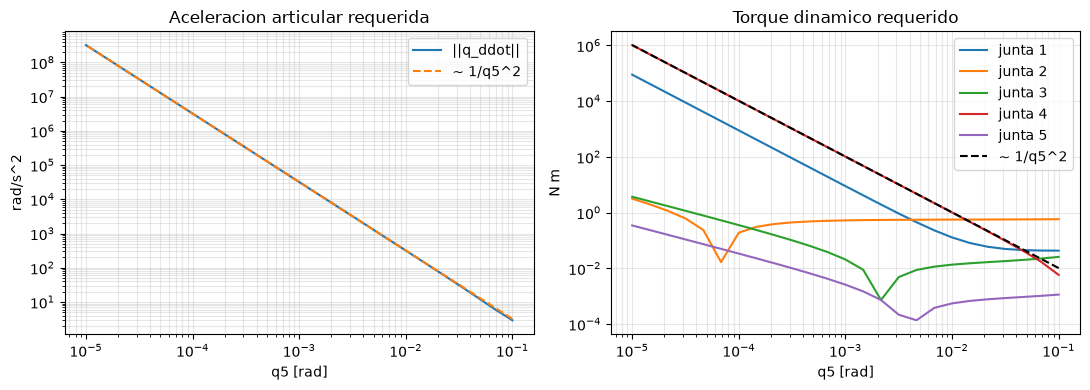

In [5]:
q5_dyn = np.logspace(-1, -5, 25)
rows = []
for e in q5_dyn:
    q = with_q5(e)
    qd, qdd, tau = dynamics.cartesian_demand(q, TWIST, ACCEL)
    rows.append((np.linalg.norm(qdd), np.abs(tau - dynamics.gravity_vector(q))))
qdd_norm = np.array([r[0] for r in rows]); tau_dyn = np.array([r[1] for r in rows])
tau_norm = np.linalg.norm(tau_dyn, axis=1)

s_qdd = np.polyfit(np.log(q5_dyn[8:]), np.log(qdd_norm[8:]), 1)[0]
s_tau = np.polyfit(np.log(q5_dyn[8:]), np.log(tau_norm[8:]), 1)[0]
print(f"Pendiente ||q_ddot||: {s_qdd:.2f}   Pendiente ||tau - g||: {s_tau:.2f}   (teoria: -2)")
print("Torque dinamico por junta [N m] en q5=1e-5:", tau_dyn[-1])
assert s_qdd < -1.8 and s_tau < -1.8

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(q5_dyn, qdd_norm, label="||q_ddot||"); ax[0].loglog(q5_dyn, qdd_norm[-1]*(q5_dyn[-1]/q5_dyn)**2, "--", label="~ 1/q5^2")
ax[0].set(xlabel="q5 [rad]", ylabel="rad/s^2", title="Aceleracion articular requerida"); ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)
for joint in range(6):
    if tau_dyn[-1, joint] > 1e-3: ax[1].loglog(q5_dyn, tau_dyn[:, joint], label=f"junta {joint+1}")
ax[1].loglog(q5_dyn, tau_norm[-1]*(q5_dyn[-1]/q5_dyn)**2, "k--", label="~ 1/q5^2")
ax[1].set(xlabel="q5 [rad]", ylabel="N m", title="Torque dinamico requerido"); ax[1].legend(); ax[1].grid(True, which="both", alpha=.3)
plt.tight_layout(); plt.show()

## 4. Consecuencia para la cinemática inversa de Pieper
En $q_5=0$ la orientación de la muñeca solo fija $q_4+q_6$; hay infinitas soluciones. `inverse_kinematics` lo marca con `singular_wrist=True` y conserva $q_4$ de referencia.

In [6]:
q_sing = np.deg2rad([10.0, 20.0, -10.0, 30.0, 0.0, 40.0])
target = forward_kinematics(q_sing)
for reference_q4 in (0.0, np.deg2rad(30.0), np.deg2rad(-50.0)):
    ref = q_sing.copy(); ref[3] = reference_q4
    best = inverse_kinematics(target, ref)[0]
    q = np.array(best.q)
    print(f"q4_ref={np.rad2deg(reference_q4):6.1f} deg -> q4={np.rad2deg(q[3]):7.2f}, q6={np.rad2deg(q[5]):7.2f}, q4+q6={np.rad2deg(q[3]+q[5]):7.2f} deg, singular={best.singular_wrist}")
    assert np.linalg.norm(forward_kinematics(q)[:3, 3] - target[:3, 3]) < 1e-9

q4_ref=   0.0 deg -> q4=   0.00, q6=  70.00, q4+q6=  70.00 deg, singular=True
q4_ref=  30.0 deg -> q4=  30.00, q6=  40.00, q4+q6=  70.00 deg, singular=True
q4_ref= -50.0 deg -> q4= -50.00, q6= 120.00, q4+q6=  70.00 deg, singular=True


## 5. Perfil LSPB sincronizado (motor de trayectorias del Hito 2)
Todas las juntas llegan a la vez con velocidad y aceleración acotadas; aquí se planifica hacia una postura cercana a la singularidad.

tf = 1.392 s, tb = 0.559 s


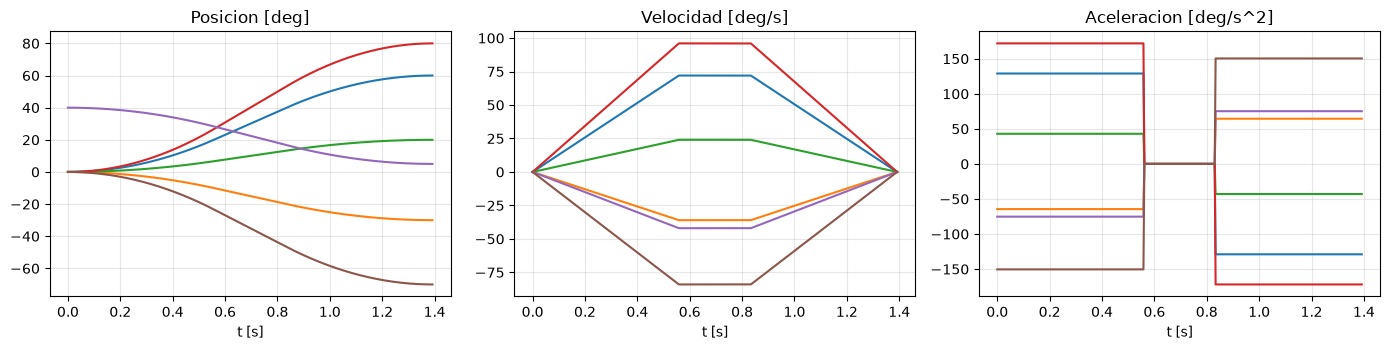

In [7]:
q_start = np.deg2rad([0, 0, 0, 0, 40, 0]); q_goal = np.deg2rad([60, -30, 20, 80, 5, -70])
trajectory = plan_lspb(q_start, q_goal, vmax=np.deg2rad(np.array([250, 250, 250, 320, 320, 420]))*0.3, amax=3.0)
times = np.linspace(0, trajectory.tf, 400)
samples = [trajectory.sample(t) for t in times]
pos, vel, acc = (np.degrees(np.array([s[i] for s in samples])) for i in range(3))
print(f"tf = {trajectory.tf:.3f} s, tb = {trajectory.tb:.3f} s")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for axis, data, title in zip(ax, (pos, vel, acc), ("Posicion [deg]", "Velocidad [deg/s]", "Aceleracion [deg/s^2]")):
    axis.plot(times, data); axis.set(xlabel="t [s]", title=title); axis.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Conclusión del pasaporte
- $\det J=-\sin q_5\,\det J_p^{brazo}$ (verificado numéricamente, error < 1e-10).
- $\|\dot q\|\propto 1/|\sin q_5|$ (pendiente log-log ≈ −1) y no existe solución en $q_5=0$ (`SingularityError`).
- $\|\ddot q\|$ y el torque dinámico $\propto 1/\sin^2 q_5$ (pendiente ≈ −2): divergen en la singularidad.
- Pieper detecta la muñeca singular y devuelve una solución válida con $q_4+q_6$ fijo.